<a href="https://colab.research.google.com/github/LennardBehmann/Intro-ML/blob/main/Homework_7/HW7_P2a_final.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Homework 7 — Problem 2.a: Deep Fully Connected Neural Network

**Goal:** CIFAR-10, 10 hidden layers (256, 256, 256, 256, 256, 256, 256, 256, 256, 256) with ReLU, 10 output logits. 80/20 split of the official 50,000 training images, plus untouched official 10,000-image test set.


## A. CIFAR-10 data loading and learning exercises

In [ ]:
import torch
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, random_split
from google.colab import drive

drive.mount("/content/drive")

Mounted at /content/drive


In [ ]:
# Convert images to PyTorch tensors
transform = transforms.ToTensor()

# Permanent storage on Google Drive
data_path = "/content/drive/MyDrive/ML_Datasets"

# Training dataset
train_dataset = datasets.CIFAR10(
    root=data_path,
    train=True,
    download=True,
    transform=transform
)

# Test dataset
test_dataset = datasets.CIFAR10(
    root=data_path,
    train=False,
    download=True,
    transform=transform
)

print("Training images:", len(train_dataset))
print("Test images:", len(test_dataset))

# Examine one image
image, label = train_dataset[0]

print("Image shape:", image.shape)
print("Class label:", label)
print("Pixel range:", image.min().item(), image.max().item())

100%|██████████| 170M/170M [13:48<00:00, 206kB/s]


Training images: 50000
Test images: 10000
Image shape: torch.Size([3, 32, 32])
Class label: 6
Pixel range: 0.0 1.0


In [ ]:
# Reproducible 80/20 split
SEED = 42
generator = torch.Generator().manual_seed(SEED)

train_set, val_set = random_split(
    train_dataset,
    [40000, 10000],
    generator=generator
)

BATCH_SIZE = 64

shuffle_generator = torch.Generator().manual_seed(SEED)

train_loader = DataLoader(
    train_set,
    batch_size=BATCH_SIZE,
    shuffle=True,
    generator=shuffle_generator
)

val_loader = DataLoader(
    val_set,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("Training images:", len(train_set))
print("Validation images:", len(val_set))
print("Test images:", len(test_dataset))

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

Training images: 40000
Validation images: 10000
Test images: 10000
Training batches: 625
Validation batches: 157
Test batches: 157


In [ ]:
import torch.nn as nn

# One training batch for the learning exercises
images, labels = next(iter(train_loader))
flat_images = images.flatten(start_dim=1)

print("Original image batch:", images.shape)
print("Flattened batch:", flat_images.shape)

# First fully connected layer
first_layer = nn.Linear(3072, 256)

# Forward pass
output = first_layer(flat_images)

print("Input shape:", flat_images.shape)
print("Output shape:", output.shape)


Original image batch: torch.Size([64, 3, 32, 32])
Flattened batch: torch.Size([64, 3072])
Input shape: torch.Size([64, 3072])
Output shape: torch.Size([64, 256])


In [ ]:

import torch
import torch.nn as nn



class CIFAR10MLP(nn.Module):
    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(
            nn.Flatten(),

            nn.Linear(3072, 256),  # Hidden Layer 1
            nn.ReLU(),

            nn.Linear(256, 256),   # Hidden Layer 2
            nn.ReLU(),

            nn.Linear(256, 256),   # Hidden Layer 3
            nn.ReLU(),

            nn.Linear(256, 256),   # Hidden Layer 4
            nn.ReLU(),

            nn.Linear(256, 256),   # Hidden Layer 5
            nn.ReLU(),

            nn.Linear(256, 256),   # Hidden Layer 6
            nn.ReLU(),

            nn.Linear(256, 256),   # Hidden Layer 7
            nn.ReLU(),

            nn.Linear(256, 256),   # Hidden Layer 8
            nn.ReLU(),

            nn.Linear(256, 256),   # Hidden Layer 9
            nn.ReLU(),

            nn.Linear(256, 256),   # Hidden Layer 10
            nn.ReLU(),

            nn.Linear(256, 10)     # Output Layer
        )

    def forward(self, x):
        return self.network(x)

model = CIFAR10MLP()
print(model)




CIFAR10MLP(
  (network): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=3072, out_features=256, bias=True)
    (2): ReLU()
    (3): Linear(in_features=256, out_features=256, bias=True)
    (4): ReLU()
    (5): Linear(in_features=256, out_features=256, bias=True)
    (6): ReLU()
    (7): Linear(in_features=256, out_features=256, bias=True)
    (8): ReLU()
    (9): Linear(in_features=256, out_features=256, bias=True)
    (10): ReLU()
    (11): Linear(in_features=256, out_features=256, bias=True)
    (12): ReLU()
    (13): Linear(in_features=256, out_features=256, bias=True)
    (14): ReLU()
    (15): Linear(in_features=256, out_features=256, bias=True)
    (16): ReLU()
    (17): Linear(in_features=256, out_features=256, bias=True)
    (18): ReLU()
    (19): Linear(in_features=256, out_features=256, bias=True)
    (20): ReLU()
    (21): Linear(in_features=256, out_features=10, bias=True)
  )
)


In [ ]:

# Forward pass through our MLP
logits = model(images)

print("Logits shape:", logits.shape)
print("Labels shape:", labels.shape)

# Define our loss function
loss_fn = nn.CrossEntropyLoss()

# Calculate the loss
loss = loss_fn(logits, labels)

print("Initial loss:", loss.item())


Logits shape: torch.Size([64, 10])
Labels shape: torch.Size([64])
Initial loss: 2.3042609691619873


In [ ]:

# Define the optimizer
optimizer = torch.optim.SGD(
    model.parameters(),
    lr=0.01
)

# 1. Reset old gradients
optimizer.zero_grad()

# 2. Forward pass
logits = model(images)
loss = loss_fn(logits, labels)

print("Loss before update:", loss.item())

# 3. Backpropagation
loss.backward()

# Inspect gradient of first linear layer
print("Gradient norm:",
      model.network[1].weight.grad.norm().item())

# 4. Update weights and biases
optimizer.step()

# 5. Recalculate loss on the same batch
with torch.no_grad():
    new_logits = model(images)
    new_loss = loss_fn(new_logits, labels)

print("Loss after update:", new_loss.item())


Loss before update: 2.3042609691619873
Gradient norm: 0.0005661109462380409
Loss after update: 2.3041064739227295


## B. Fresh deep model and training configuration

**Important:** The exercises above used one training batch from the training split. Here we create a **new** model, so the demonstration update is not included in the experiment. The final layer produces raw logits (do **not** apply Softmax before `CrossEntropyLoss`).

In [ ]:
import random
import numpy as np
from pathlib import Path

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = CIFAR10MLP().to(device)  # freshly initialized

# He initialization for ReLU hidden layers
for layer in model.network:
    if isinstance(layer, nn.Linear) and layer.out_features == 256:
        nn.init.kaiming_normal_(
            layer.weight,
            nonlinearity="relu"
        )
        nn.init.zeros_(layer.bias)

loss_fn = nn.CrossEntropyLoss()
LEARNING_RATE = 0.01
optimizer = torch.optim.SGD(model.parameters(), lr=LEARNING_RATE)
NUM_EPOCHS = 80

output_dir = Path("/content/drive/MyDrive/ML_Checkpoints")
output_dir.mkdir(parents=True, exist_ok=True)

n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print("Device:", device)
print("Architecture:", model)
print("Trainable parameters:", f"{n_params:,}")
assert n_params == 1381386

Device: cuda
Architecture: CIFAR10MLP(
  (network): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=3072, out_features=256, bias=True)
    (2): ReLU()
    (3): Linear(in_features=256, out_features=256, bias=True)
    (4): ReLU()
    (5): Linear(in_features=256, out_features=256, bias=True)
    (6): ReLU()
    (7): Linear(in_features=256, out_features=256, bias=True)
    (8): ReLU()
    (9): Linear(in_features=256, out_features=256, bias=True)
    (10): ReLU()
    (11): Linear(in_features=256, out_features=256, bias=True)
    (12): ReLU()
    (13): Linear(in_features=256, out_features=256, bias=True)
    (14): ReLU()
    (15): Linear(in_features=256, out_features=256, bias=True)
    (16): ReLU()
    (17): Linear(in_features=256, out_features=256, bias=True)
    (18): ReLU()
    (19): Linear(in_features=256, out_features=256, bias=True)
    (20): ReLU()
    (21): Linear(in_features=256, out_features=10, bias=True)
  )
)
Trainable parameters: 1,381,386


## C. Evaluation function

In evaluation mode, use **no gradients** and **no optimizer step**. Weight the mean batch loss by the number of images, so the last, smaller batch receives the correct weight.

In [ ]:
def evaluate(model, data_loader, loss_fn, device):
    model.eval()
    loss_sum = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for batch_images, batch_labels in data_loader:
            batch_images = batch_images.to(device)
            batch_labels = batch_labels.to(device)

            logits = model(batch_images)
            loss = loss_fn(logits, batch_labels)

            batch_size = batch_labels.size(0)
            loss_sum += loss.item() * batch_size
            correct += (logits.argmax(dim=1) == batch_labels).sum().item()
            total += batch_size

    return loss_sum / total, correct / total

## D. Training, timing, curves, and best validation checkpoint

Each epoch processes all **40,000** training images in **625** SGD steps. `training_seconds` includes the train-batch computation only; `total_experiment_seconds` also includes per-epoch validation. GPU synchronization makes the timing more trustworthy on CUDA.

We use the **lowest validation loss** to select the best epoch. The test set is **never** consulted inside this loop.

In [ ]:
import copy
import time

train_losses, val_losses = [], []
train_accuracies, val_accuracies = [], []
epoch_train_seconds = []

best_val_loss = float("inf")
best_val_epoch = None
best_val_accuracy = None
best_state = None
training_seconds = 0.0

# Synchronize only on CUDA to avoid measuring merely enqueued GPU work.
def synchronize_if_cuda():
    if device.type == "cuda":
        torch.cuda.synchronize()

synchronize_if_cuda()
experiment_start = time.perf_counter()

for epoch in range(1, NUM_EPOCHS + 1):
    model.train()
    train_loss_sum = 0.0
    train_correct = 0
    train_count = 0

    synchronize_if_cuda()
    epoch_start = time.perf_counter()

    for batch_images, batch_labels in train_loader:
        batch_images = batch_images.to(device)
        batch_labels = batch_labels.to(device)

        optimizer.zero_grad()
        logits = model(batch_images)
        loss = loss_fn(logits, batch_labels)
        loss.backward()
        optimizer.step()

        count = batch_labels.size(0)
        train_loss_sum += loss.item() * count
        train_correct += (logits.argmax(dim=1) == batch_labels).sum().item()
        train_count += count

    synchronize_if_cuda()
    epoch_seconds = time.perf_counter() - epoch_start
    epoch_train_seconds.append(epoch_seconds)
    training_seconds += epoch_seconds

    # Online training metrics: computed as weights change during the epoch.
    train_loss = train_loss_sum / train_count
    train_acc = train_correct / train_count

    # Validation metrics: computed AFTER that epoch with fixed weights.
    val_loss, val_acc = evaluate(model, val_loader, loss_fn, device)

    train_losses.append(train_loss)
    val_losses.append(val_loss)
    train_accuracies.append(train_acc)
    val_accuracies.append(val_acc)

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_val_epoch = epoch
        best_val_accuracy = val_acc
        best_state = copy.deepcopy(model.state_dict())

    print(
        f"Epoch {epoch:2d}/{NUM_EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f} | "
        f"Train Acc: {train_acc:.2%} | Val Acc: {val_acc:.2%} | "
        f"Train Time: {epoch_seconds:.1f}s"
    )

synchronize_if_cuda()
total_experiment_seconds = time.perf_counter() - experiment_start

# Save checkpoint and restore best validation-loss weights.
checkpoint_path = output_dir / "p2a_he_best_model.pt"
torch.save(best_state, checkpoint_path)
model.load_state_dict(best_state)

print("\nBest validation-loss epoch:", best_val_epoch)
print("Best validation loss:", round(best_val_loss, 4))
print("Validation accuracy at best-loss epoch:", f"{best_val_accuracy:.2%}")
print("Training time (excludes validation):", f"{training_seconds:.1f} seconds")
print("Total training + validation runtime:", f"{total_experiment_seconds:.1f} seconds")
print("Best checkpoint saved to:", checkpoint_path)

Epoch  1/80 | Train Loss: 2.0061 | Val Loss: 1.8511 | Train Acc: 26.55% | Val Acc: 32.37% | Train Time: 9.0s
Epoch  2/80 | Train Loss: 1.7976 | Val Loss: 1.7787 | Train Acc: 35.06% | Val Acc: 36.33% | Train Time: 5.9s
Epoch  3/80 | Train Loss: 1.7088 | Val Loss: 1.6526 | Train Acc: 38.45% | Val Acc: 40.55% | Train Time: 7.0s
Epoch  4/80 | Train Loss: 1.6512 | Val Loss: 1.6075 | Train Acc: 40.91% | Val Acc: 42.90% | Train Time: 6.0s
Epoch  5/80 | Train Loss: 1.6006 | Val Loss: 1.5814 | Train Acc: 42.72% | Val Acc: 43.27% | Train Time: 6.8s
Epoch  6/80 | Train Loss: 1.5648 | Val Loss: 1.5599 | Train Acc: 44.06% | Val Acc: 43.76% | Train Time: 6.4s
Epoch  7/80 | Train Loss: 1.5282 | Val Loss: 1.6029 | Train Acc: 45.03% | Val Acc: 42.11% | Train Time: 6.1s
Epoch  8/80 | Train Loss: 1.5013 | Val Loss: 1.5152 | Train Acc: 46.24% | Val Acc: 46.26% | Train Time: 6.8s
Epoch  9/80 | Train Loss: 1.4676 | Val Loss: 1.6027 | Train Acc: 47.43% | Val Acc: 43.86% | Train Time: 6.0s
Epoch 10/80 | Train

## E. Final evaluation (once, after selecting the checkpoint)

Evaluate **the same selected checkpoint** on training, validation and test images. Unlike the online training metrics in the curves, these three metrics all use fixed weights and are directly comparable. The test result should be reported as **test / evaluation accuracy**, not confused with validation accuracy.

In [ ]:
# Checkpoint is already loaded into model above.
selected_train_loss, selected_train_acc = evaluate(model, train_loader, loss_fn, device)
selected_val_loss, selected_val_acc = evaluate(model, val_loader, loss_fn, device)
selected_test_loss, selected_test_acc = evaluate(model, test_loader, loss_fn, device)

print(f"Selected checkpoint: epoch {best_val_epoch} (of max {NUM_EPOCHS})")
print(f"Training Loss:     {selected_train_loss:.4f}")
print(f"Training Accuracy: {selected_train_acc:.2%}")
print(f"Validation Loss:   {selected_val_loss:.4f}")
print(f"Validation Accuracy: {selected_val_acc:.2%}")
print(f"Test Loss:         {selected_test_loss:.4f}")
print(f"Test Accuracy:     {selected_test_acc:.2%}")
print(f"Parameters:        {n_params:,}")
print(f"Training Time:     {training_seconds:.1f}s (training only)")
print(f"Train-Test Gap:    {(selected_train_acc - selected_test_acc)*100:.2f} percentage points")

Selected checkpoint: epoch 22 (of max 80)
Training Loss:     1.1291
Training Accuracy: 59.95%
Validation Loss:   1.4099
Validation Accuracy: 50.28%
Test Loss:         1.4190
Test Accuracy:     50.21%
Parameters:        1,381,386
Training Time:     528.0s (training only)
Train-Test Gap:    9.74 percentage points


## F. Training curves (required for report)


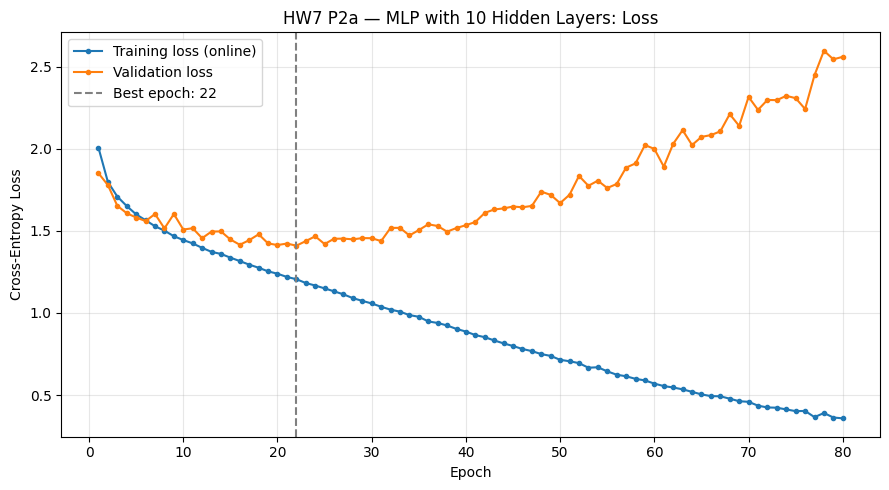

In [ ]:
import matplotlib.pyplot as plt

epochs = range(1, len(train_losses) + 1)

plt.figure(figsize=(9, 5))
plt.plot(epochs, train_losses, marker="o", markersize=3, label="Training loss (online)")
plt.plot(epochs, val_losses, marker="o", markersize=3, label="Validation loss")
plt.axvline(best_val_epoch, color="gray", linestyle="--", label=f"Best epoch: {best_val_epoch}")
plt.xlabel("Epoch")
plt.ylabel("Cross-Entropy Loss")
plt.title("HW7 P2a — MLP with 10 Hidden Layers: Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

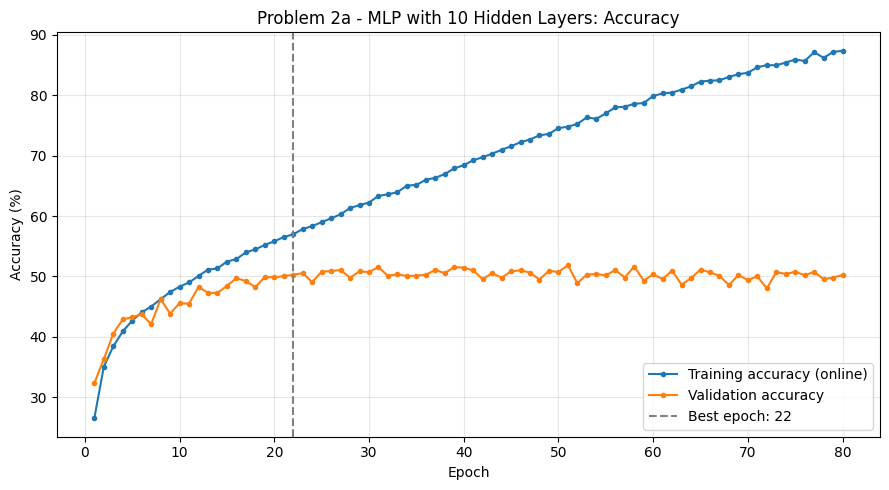

In [ ]:
plt.figure(figsize=(9, 5))
plt.plot(epochs, [100*x for x in train_accuracies], marker="o", markersize=3, label="Training accuracy (online)")
plt.plot(epochs, [100*x for x in val_accuracies], marker="o", markersize=3, label="Validation accuracy")
plt.axvline(best_val_epoch, color="gray", linestyle="--", label=f"Best epoch: {best_val_epoch}")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("Problem 2a - MLP with 10 Hidden Layers: Accuracy")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:

# Examine gradients of different layers
model.train()

batch_images, batch_labels = next(iter(train_loader))
batch_images = batch_images.to(device)
batch_labels = batch_labels.to(device)

optimizer.zero_grad()

logits = model(batch_images)
loss = loss_fn(logits, batch_labels)
loss.backward()

# Compare gradients across the network
for i in [1, 3, 11, 19, 21]:
    gradient = model.network[i].weight.grad
    print(f"Layer {i}: {gradient.norm().item():.8f}")

optimizer.zero_grad()


Layer 1: 4.90674686
Layer 3: 1.81273842
Layer 11: 1.33586466
Layer 19: 0.75139922
Layer 21: 1.03559697
